# 11. Interpretabilidad global y local (SHAP y LIME)

Los valores de Shapley reparten la predicción de un caso entre sus variables según la teoría de
juegos cooperativos: la contribución de una variable es su aporte marginal promedio sobre todos
los órdenes posibles de incorporación. Cumplen **eficiencia** (las contribuciones suman la
diferencia entre la predicción y el valor base), **simetría** (dos variables que aportan lo mismo
reciben lo mismo) y **aditividad** (en un ensamble, los SHAP del ensamble son la suma de los de sus
partes). Se calculan en el espacio que ve el modelo (columnas one-hot), así que cada barra es una
categoría concreta, por ejemplo `soc_minor=29-1` (profesionales de la salud).

Se explica el mejor modelo de cada tarea (según la validación anidada) y, como pide la guía, el
mejor XGBoost de clasificación con SHAP y LIME.

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
from osha_e3 import config as C, data as D, models as M, nested as N, final as F, plots as P, search as S, interpret as I, cache
P.setup()
mc, mr = N.master_table('clf'), N.master_table('reg')
bc = mc.loc[mc.outer_recall_mean.idxmax()]; br = mr.loc[mr.outer_rmse_mean.idxmin()]
bx = mc[mc.model == 'xgboost'].sort_values('outer_recall_mean').iloc[-1]
print('Mejor clasificación:', bc.combo, '| mejor regresión:', br.combo, '| mejor XGBoost:', bx.combo)
Xc, yc, _, _ = N.task_data('clf'); Xr, yr, _, _ = N.task_data('reg')
test_c, yt_c = F.test_data('clf'); test_r, yt_r = F.test_data('reg')
rng = np.random.default_rng(C.SEED)
ic = rng.choice(len(test_c), 1500, replace=False); ir = rng.choice(len(test_r), 1500, replace=False)
CLASS = 1  # «días de ausencia»: la clase más frecuente y la de mayor costo laboral

Mejor clasificación: svm|smote|random | mejor regresión: random_forest|none|random | mejor XGBoost: xgboost|class_weight|bayes


In [2]:
def explain(task, row, Xtr, ytr, Xex):
    pipe = S.refit(task, row.model, json.loads(row.final_params), row.balance, Xtr, ytr, C.SEED)
    vals, base, A, names = I.shap_values(task, row.model, pipe, Xtr.sample(1000, random_state=C.SEED), Xex)
    return pipe, vals, base, A, names
pipe_c, sv_c, base_c, A_c, names = cache.cached('shap_clf', lambda: explain('clf', bc, Xc, yc, test_c[D.FEATURES].iloc[ic]))
pipe_r, sv_r, base_r, A_r, names_r = cache.cached('shap_reg', lambda: explain('reg', br, Xr, yr, test_r[D.FEATURES].iloc[ir]))
print('SHAP clasificación:', sv_c.shape, '| regresión:', sv_r.shape)

SHAP clasificación: (1500, 231, 4) | regresión: (1500, 220)


## 11.1 Clasificación: interpretabilidad global

Gráfico resumen para la clase «días de ausencia» (salida del modelo antes de softmax, en log-odds
si el modelo es de árboles o lineal). Cada punto es un caso de la prueba; el color indica si la
categoría está presente (1, rojo) o no (0, azul).

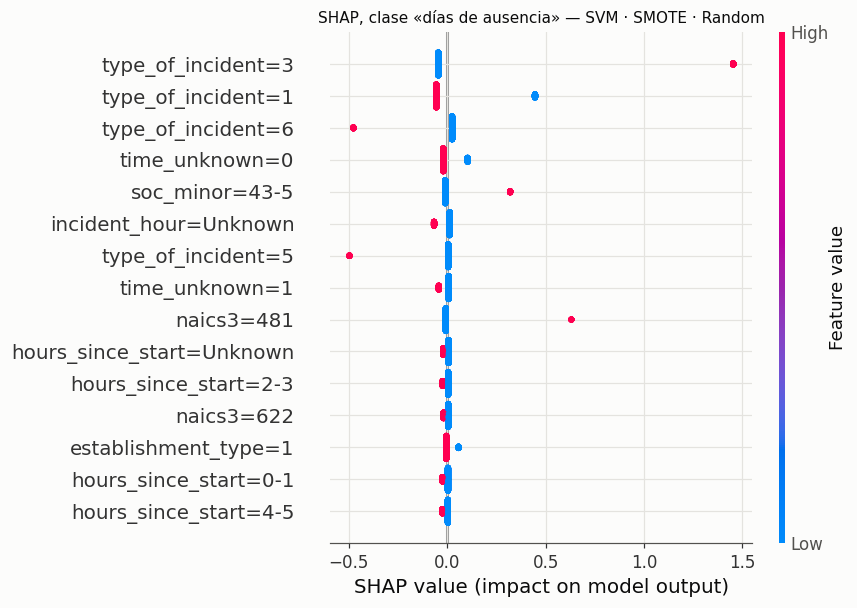

In [3]:
sv1 = sv_c[:, :, CLASS] if sv_c.ndim == 3 else sv_c
plt.figure()
shap.summary_plot(sv1, A_c, feature_names=names, max_display=15, show=False, plot_size=(8, 5.5))
plt.title(f'SHAP, clase «días de ausencia» — {M.PRETTY[bc.model]} · {M.PRETTY[bc.balance]} · {M.PRETTY[bc.optimizer]}', fontsize=10)
P.save(plt.gcf(), 'e3_shap_clf_summary'); plt.show()

In [4]:
imp = pd.DataFrame({C.CLASS_NAMES[k]: np.abs(sv_c[:, :, k]).mean(0) for k in range(sv_c.shape[2])}, index=names) if sv_c.ndim == 3 \
    else pd.DataFrame({'|SHAP| medio': np.abs(sv_c).mean(0)}, index=names)
imp['total'] = imp.sum(axis=1)
by_var = imp.groupby(lambda n: n.split('=')[0]).sum().sort_values('total', ascending=False)
print('Importancia por variable original (suma de |SHAP| medio de sus categorías):')
display(by_var.round(4))
imp.sort_values('total', ascending=False).head(12).round(4)

Importancia por variable original (suma de |SHAP| medio de sus categorías):


,Fallecimiento,Días de ausencia,Traslado/restricción,Otro registrable,total
naics3,0.4397,0.0558,0.2746,0.4950,1.2650
soc_minor,0.2941,0.0533,0.0344,0.2548,0.6366
type_of_incident,0.1873,0.2893,0.0300,0.1042,0.6109
state,0.4556,0.0167,0.0166,0.0148,0.5037
hours_since_start,0.2668,0.0473,0.0883,0.0853,0.4878
incident_hour,0.2967,0.0304,0.0576,0.0566,0.4412
start_hour,0.3463,0.0165,0.0307,0.0297,0.4231
time_unknown,0.1084,0.0454,0.0874,0.0861,0.3273
establishment_type,0.0608,0.0151,0.0283,0.0343,0.1385


,Fallecimiento,Días de ausencia,Traslado/restricción,Otro registrable,total
naics3=622,0.1380,0.0079,0.0194,0.2829,0.4482
time_unknown=0,0.0929,0.0322,0.0621,0.0616,0.2487
type_of_incident=1,0.1154,0.1034,0.0141,0.0065,0.2395
type_of_incident=3,0.0129,0.1229,0.0061,0.0767,0.2185
soc_minor=29-1,0.0348,0.0023,0.0024,0.1720,0.2115
naics3=452,0.0388,0.0040,0.0099,0.1309,0.1836
naics3=713,0.0256,0.0021,0.1249,0.0058,0.1585
state=CA,0.1228,0.0024,0.0021,0.0017,0.1289
soc_minor=53-7,0.1078,0.0039,0.0039,0.0108,0.1263
start_hour=7,0.1124,0.0022,0.0041,0.0039,0.1226


**Interpretación.** El mejor modelo de clasificación según la validación anidada es SVM lineal con SMOTE (búsqueda
aleatoria), así que sus SHAP son exactos y aditivos en la escala de la función de decisión. Para la clase
«días de ausencia» domina el **tipo de incidente**: una enfermedad respiratoria (`type_of_incident=3`)
empuja con fuerza hacia días de ausencia (+1,45), y las enfermedades «otras» (6) y la pérdida auditiva (5)
empujan en contra (−0,5). Le siguen categorías concretas de sector y ocupación (transporte aéreo,
`naics3=481`; ocupaciones de despacho y distribución, `soc_minor=43-5`). Sumando todas las clases, el
orden de las variables es subsector NAICS > grupo SOC > tipo de incidente > estado, el mismo que la V de
Cramér del capítulo 4. Las horas aportan poco. `time_unknown` aparece con peso propio, pero es la misma
información que `incident_hour=Unknown` (sección 4.6): las dos columnas se reparten el crédito.

Las contribuciones a Fallecimiento son grandes y dispersas (estado, hora de inicio, sector). Con 9
fallecimientos reales y miles sintéticos de SMOTE, el modelo aprendió a reconocer las combinaciones de
esos pocos casos, no un patrón general; por eso esas contribuciones no se interpretan.

## 11.2 Clasificación: interpretabilidad local

Dos casos de la muestra explicada: uno bien clasificado como «días de ausencia» con alta
probabilidad, y uno cuya clase real es «días de ausencia» pero que el modelo asignó con
confianza a otra clase (error elevado).

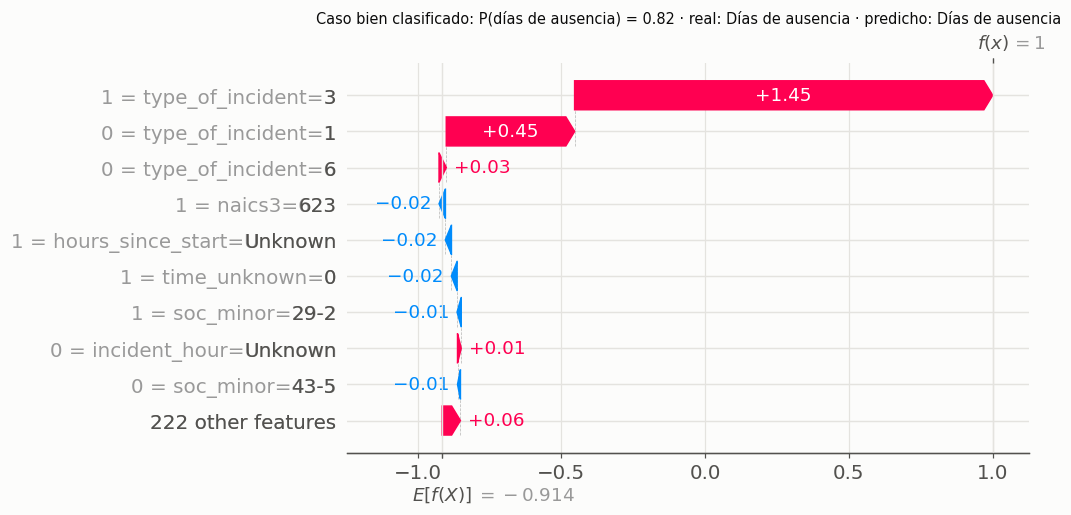

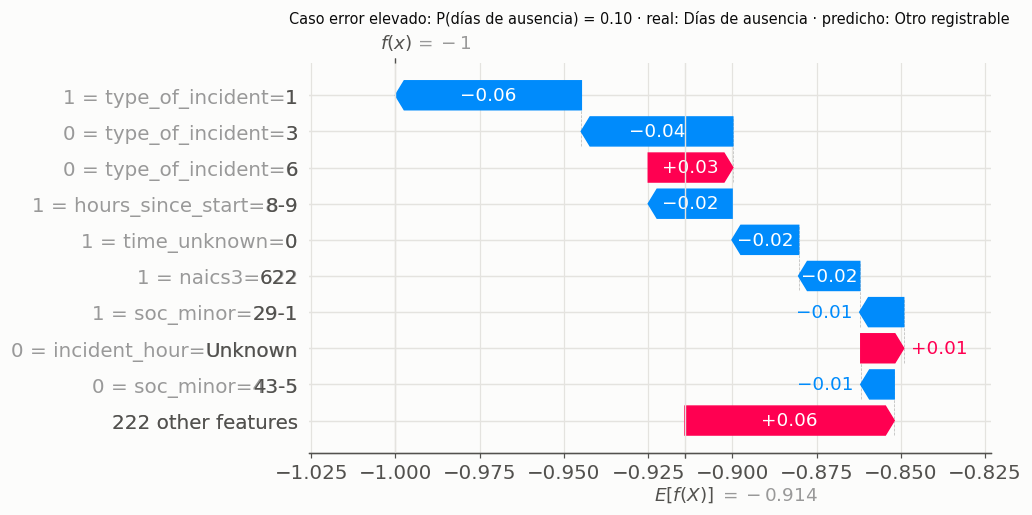

,bien clasificado,error elevado
state,CT,PA
naics3,623,622
establishment_type,1,1
soc_minor,29-2,29-1
type_of_incident,3,1
time_unknown,0,0
start_hour,Unknown,7
incident_hour,12,16
hours_since_start,Unknown,8-9


In [5]:
pc = pipe_c.predict_proba(test_c[D.FEATURES].iloc[ic]); yy = yt_c[ic]
ok = np.where((pc.argmax(1) == CLASS) & (yy == CLASS))[0]; ok = ok[np.argmax(pc[ok, CLASS])]
bad = np.where((pc.argmax(1) != CLASS) & (yy == CLASS))[0]; bad = bad[np.argmin(pc[bad, CLASS])]
for i, title, fname in [(ok, 'bien clasificado', 'e3_shap_clf_waterfall_ok'), (bad, 'error elevado', 'e3_shap_clf_waterfall_error')]:
    b = base_c[CLASS] if np.ndim(base_c) else base_c
    shap.plots.waterfall(shap.Explanation(sv1[i], b, A_c[i], feature_names=names), max_display=10, show=False)
    plt.gcf().set_size_inches(8, 4.6)
    plt.title(f'Caso {title}: P(días de ausencia) = {pc[i, CLASS]:.2f} · real: {C.CLASS_NAMES[yy[i]]} · '
              f'predicho: {C.CLASS_NAMES[pc[i].argmax()]}', fontsize=9.5)
    P.save(plt.gcf(), fname); plt.show()
pd.DataFrame({'bien clasificado': test_c[D.FEATURES].iloc[ic].iloc[ok], 'error elevado': test_c[D.FEATURES].iloc[ic].iloc[bad]})

**Interpretación.** **Caso bien clasificado:** una enfermedad respiratoria de un técnico de salud (`soc_minor=29-2`) en un
centro de cuidados de enfermería (`naics3=623`). La enfermedad respiratoria aporta casi toda la
decisión (+1,45); el resto de variables apenas la mueve. Es el patrón más claro del archivo: muchas
ausencias cortas por enfermedad respiratoria en el sector salud.

**Caso con error elevado:** una lesión (`type_of_incident=1`) de un profesional de la salud
(`soc_minor=29-1`) en un hospital (`naics3=622`) que terminó en días de ausencia, pero el modelo le dio
solo 0,10 de probabilidad y lo clasificó como «otro registrable». Ser lesión y no enfermedad resta, y el
hospital y la ocupación sanitaria también empujan hacia «otro registrable» (en los hospitales muchas
lesiones se registran sin días perdidos). Lo que hizo que este caso terminara en ausencia (la gravedad
de la lesión, la parte del cuerpo, la política del empleador) no está entre las variables del modelo:
el error no es un defecto del ajuste sino un límite de la información disponible.

## 11.3 Regresión: interpretabilidad global y local

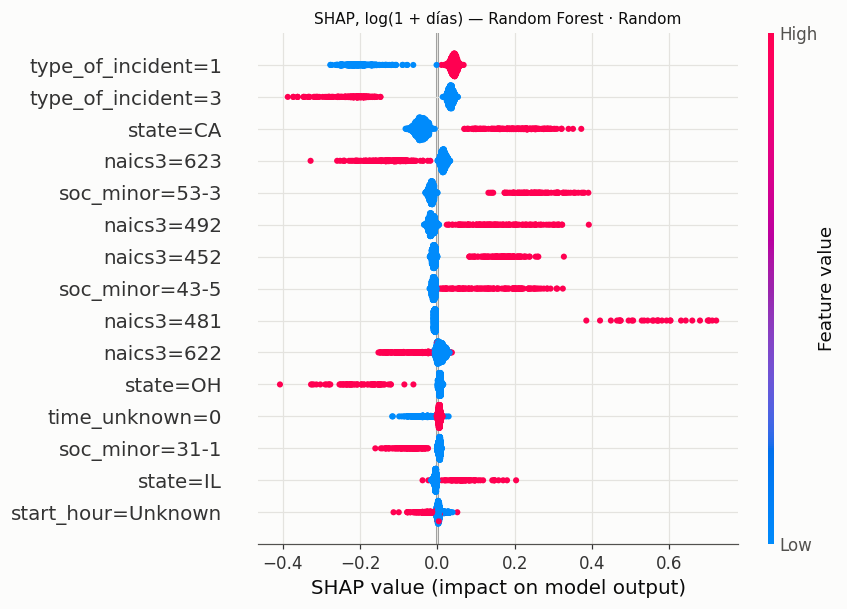

,suma |SHAP| medio
naics3,0.1680
state,0.1487
type_of_incident,0.1406
soc_minor,0.0991
start_hour,0.0471
incident_hour,0.0322
hours_since_start,0.0286
time_unknown,0.0164
establishment_type,0.0039


In [6]:
plt.figure()
shap.summary_plot(sv_r, A_r, feature_names=names_r, max_display=15, show=False, plot_size=(8, 5.5))
plt.title(f'SHAP, log(1 + días) — {M.PRETTY[br.model]} · {M.PRETTY[br.optimizer]}', fontsize=10)
P.save(plt.gcf(), 'e3_shap_reg_summary'); plt.show()
imp_r = pd.Series(np.abs(sv_r).mean(0), index=names_r)
imp_r.groupby(lambda n: n.split('=')[0]).sum().sort_values(ascending=False).round(4).to_frame('suma |SHAP| medio')

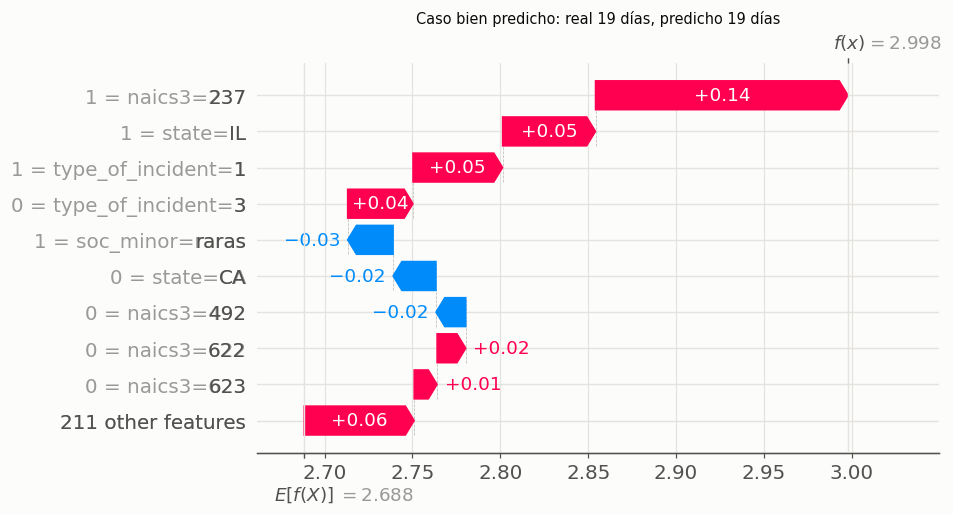

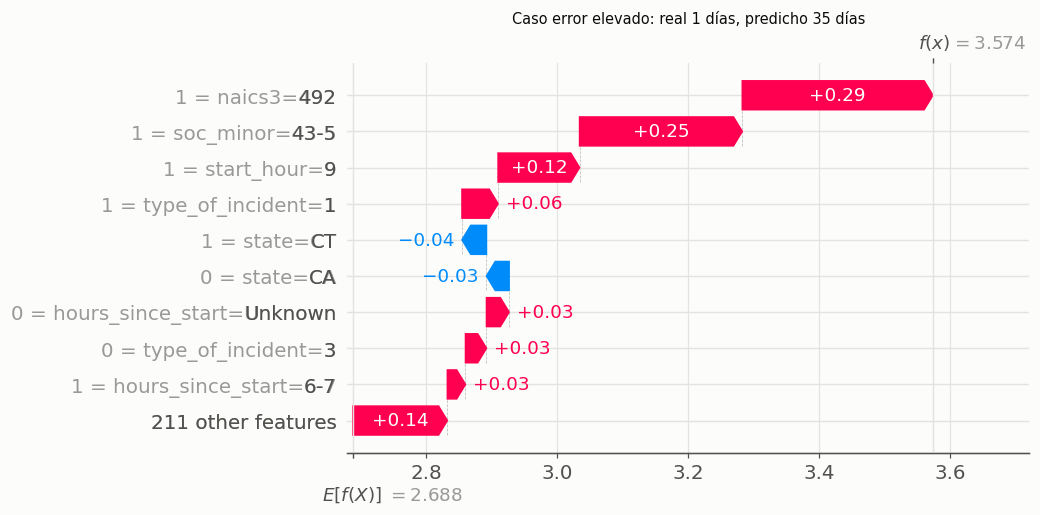

,bien predicho,error elevado
state,IL,CT
naics3,237,492
establishment_type,3,1
soc_minor,47-4,43-5
type_of_incident,1,1
time_unknown,0,0
start_hour,7,9
incident_hour,13,16
hours_since_start,6-7,6-7


In [7]:
pr = pipe_r.predict(test_r[D.FEATURES].iloc[ir]); er = np.abs(yt_r[ir] - pr)
good, worst = int(np.argmin(er)), int(np.argmax(er))
for i, title, fname in [(good, 'bien predicho', 'e3_shap_reg_waterfall_ok'), (worst, 'error elevado', 'e3_shap_reg_waterfall_error')]:
    shap.plots.waterfall(shap.Explanation(sv_r[i], float(np.ravel(base_r)[0]), A_r[i], feature_names=names_r), max_display=10, show=False)
    plt.gcf().set_size_inches(8, 4.6)
    plt.title(f'Caso {title}: real {np.expm1(yt_r[ir][i]):.0f} días, predicho {np.expm1(pr[i]):.0f} días', fontsize=9.5)
    P.save(plt.gcf(), fname); plt.show()
pd.DataFrame({'bien predicho': test_r[D.FEATURES].iloc[ir].iloc[good], 'error elevado': test_r[D.FEATURES].iloc[ir].iloc[worst]})

**Interpretación.** En regresión (Random Forest), las variables más importantes son subsector, estado, tipo de incidente y
grupo ocupacional, con aportes de la misma magnitud (0,10 a 0,17 de |SHAP| medio en log-días); las horas
aportan poco. El estado pesa más que en clasificación, lo que es coherente con la variación entre estados
de la proporción de días de ausencia que mostró el EDA del entregable 2 (23,5 % a 69,2 %), atribuible a
prácticas de registro y a reglas de compensación laboral de cada estado (inferencia, no comprobada).

**Caso bien predicho:** 19 días reales y 19 predichos en un caso de construcción pesada (`naics3=237`) en
Illinois: el subsector sube la predicción por encima del promedio (2,69 en escala log, unos 14 días).
**Caso con error elevado:** 1 día real y 35 predichos. Un trabajador de despacho y distribución
(`soc_minor=43-5`) en mensajería y reparto (`naics3=492`): sector y ocupación están asociados a ausencias
largas en promedio, pero este caso fue una ausencia de un día. El modelo predice el promedio de casos
parecidos y no puede distinguir una ausencia corta de una larga dentro del mismo perfil, otra vez
porque no ve la lesión concreta. Este es el patrón típico del R² bajo del capítulo 10.

## 11.4 XGBoost: SHAP frente a LIME

Se explica el mismo caso con las dos técnicas, para la clase «días de ausencia».

- **SHAP (TreeExplainer)** calcula valores de Shapley exactos para el ensamble de árboles,
  usando la cobertura de cada rama de los árboles (*tree path dependent*). Las contribuciones
  suman exactamente la salida del modelo (log-odds) menos el valor base. Se agregan por variable
  original sumando sus categorías (válido por aditividad) para compararlas con LIME.
- **LIME** perturba el caso (aquí, cambia la categoría de algunas de las 9 variables por otra
  observada en el entrenamiento y pasa cada fila por el pipeline completo), pondera las perturbaciones
  por cercanía y ajusta un modelo **lineal local** sobre la probabilidad. Sus coeficientes
  dependen del núcleo de proximidad, del muestreo y de la semilla, y no tienen por qué sumar la
  predicción.

In [8]:
def run_xgb_explain():
    pipe = S.refit('clf', 'xgboost', json.loads(bx.final_params), bx.balance, Xc, yc, C.SEED)
    rows = test_c[D.FEATURES].iloc[ic[:300]]
    vals, base, A, nm = I.shap_values('clf', 'xgboost', pipe, Xc.sample(1000, random_state=C.SEED), rows)
    return pipe, vals, base, A, nm
pipe_x, sv_x, base_x, A_x, names_x = cache.cached('shap_xgb_v2', run_xgb_explain)
rows_x = test_c[D.FEATURES].iloc[ic[:300]]
px = pipe_x.predict_proba(rows_x)
margin = pipe_x.named_steps['model'].predict(pipe_x.named_steps['onehot'].transform(rows_x), output_margin=True)
print('Aditividad SHAP (máx. |suma SHAP + base − salida del modelo|):',
      float(np.abs(sv_x.sum(axis=1) + base_x - margin).max()))
case = int(np.argmax(px[:, CLASS]))
x_case = rows_x.iloc[[case]]
print(f'Caso explicado: P(días de ausencia) = {px[case, CLASS]:.3f}')
display(x_case.T.rename(columns=lambda c: 'categoría del caso'))

Aditividad SHAP (máx. |suma SHAP + base − salida del modelo|): 1.6689300537109375e-06
Caso explicado: P(días de ausencia) = 0.899


,categoría del caso
state,NC
naics3,622
establishment_type,1
soc_minor,37-2
type_of_incident,3
time_unknown,1
start_hour,Unknown
incident_hour,Unknown
hours_since_start,Unknown


In [9]:
shap_var = I.group_by_variable(sv_x[:, :, CLASS], names_x).iloc[case]
lime_runs = cache.cached('lime_xgb_v2', lambda: [I.lime_explain(pipe_x, Xc.sample(5000, random_state=C.SEED), x_case, CLASS, seed=s)
                                                for s in [C.SEED, C.SEED + 1, C.SEED + 2]])
def lime_by_var(run):
    return pd.Series({k.split('=')[0]: v for k, v in run})
lime_tab = pd.DataFrame({f'LIME semilla {s}': lime_by_var(r) for s, r in zip([C.SEED, C.SEED + 1, C.SEED + 2], lime_runs)}).reindex(D.FEATURES)
comp = pd.DataFrame({'SHAP (log-odds, suma de la variable)': shap_var}).join(lime_tab)
comp['rango SHAP'] = comp.iloc[:, 0].abs().rank(ascending=False)
comp['rango LIME (semilla 42)'] = comp[f'LIME semilla {C.SEED}'].abs().rank(ascending=False)
display(comp.round(4))
from scipy.stats import spearmanr
rho, p = spearmanr(comp.iloc[:, 0].abs(), comp[f'LIME semilla {C.SEED}'].abs())
signs = (np.sign(comp.iloc[:, 0]) == np.sign(comp[f'LIME semilla {C.SEED}'])).mean()
stab = lime_tab.std(axis=1).mean()
print(f'Spearman entre |SHAP| y |LIME| por variable: {rho:.2f} | signos coincidentes: {signs:.0%} | '
      f'd.e. media de LIME entre semillas: {stab:.4f}')

,"SHAP (log-odds, suma de la variable)",LIME semilla 42,LIME semilla 43,LIME semilla 44,rango SHAP,rango LIME (semilla 42)
state,-0.0171,-0.0236,-0.0247,-0.0205,7.0,4.0
naics3,0.0261,-0.0639,-0.0630,-0.0663,6.0,3.0
establishment_type,-0.0130,-0.0846,-0.0759,-0.0679,8.0,2.0
soc_minor,0.0952,0.0119,0.0210,0.0199,3.0,5.0
type_of_incident,1.7438,0.3574,0.3563,0.3596,1.0,1.0
time_unknown,0.1576,0.0039,0.0033,0.0042,2.0,8.0
start_hour,0.0408,0.0043,0.0022,0.0013,4.0,6.0
incident_hour,0.0403,-0.0040,-0.0008,-0.0029,5.0,7.0
hours_since_start,-0.0058,-0.0010,-0.0070,-0.0076,9.0,9.0


Spearman entre |SHAP| y |LIME| por variable: 0.15 | signos coincidentes: 78% | d.e. media de LIME entre semillas: 0.0029


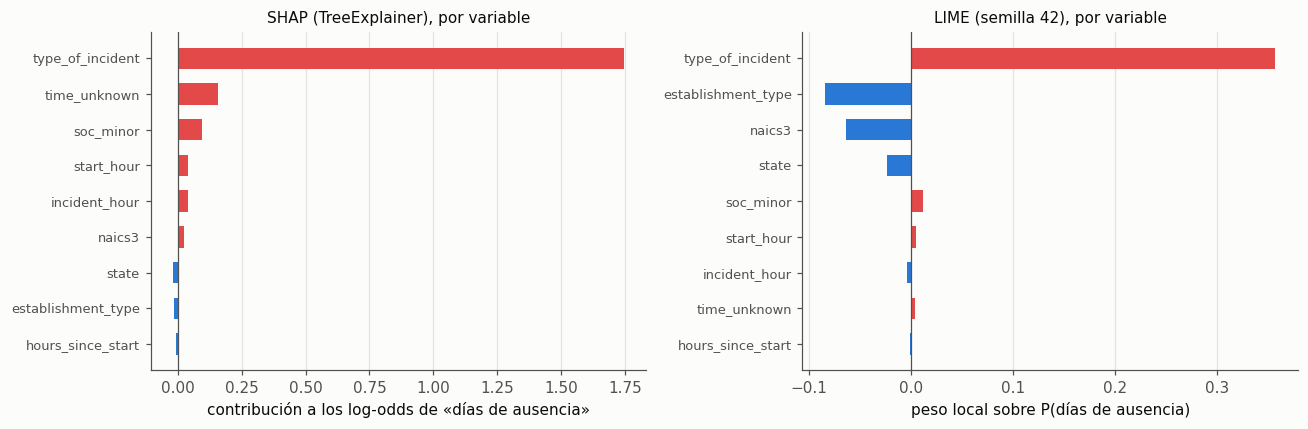

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, s, title, xl in [(axes[0], comp.iloc[:, 0], 'SHAP (TreeExplainer), por variable', 'contribución a los log-odds de «días de ausencia»'),
                         (axes[1], comp[f'LIME semilla {C.SEED}'], 'LIME (semilla 42), por variable', 'peso local sobre P(días de ausencia)')]:
    s = s.reindex(s.abs().sort_values().index)
    ax.barh(range(len(s)), s.values, color=[P.SERIES[7] if v > 0 else P.SERIES[0] for v in s.values], height=0.6)
    ax.set_yticks(range(len(s)), s.index, fontsize=8.5); ax.axvline(0, color=P.INK2, lw=0.8)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.grid(axis='y', visible=False)
fig.tight_layout(); P.save(fig, 'e3_shap_vs_lime'); plt.show()

**Interpretación.** Las dos técnicas coinciden en lo principal: para este caso (una enfermedad respiratoria en un hospital,
P(días de ausencia) = 0,90 con XGBoost), las dos ponen el tipo de incidente en primer lugar y con signo
positivo. En el resto discrepan: la correlación de rangos entre |SHAP| y |LIME| de las 9 variables es
solo 0,15 y los signos coinciden en el 78 % de las variables. SHAP pone en segundo lugar `time_unknown`
(el caso tiene la hora desconocida); LIME casi no le da peso y, en cambio, da peso negativo al tipo de
establecimiento y al subsector, que para SHAP son casi nulos. LIME es estable entre semillas en este caso
(desviación media de 0,003 entre las 3 semillas).

Las diferencias tienen explicación: (1) LIME mide el efecto de *cambiar* una variable a otro valor
típico, en la escala de probabilidad, y promedia ese efecto con un modelo lineal en un vecindario; SHAP
reparte la salida del modelo en log-odds según los caminos de los árboles. (2) `time_unknown`, la hora y
las horas desde el inicio son redundantes: SHAP les asigna crédito a ellas según la estructura de los
árboles, mientras que LIME, al cambiar una sola a la vez, crea filas incoherentes (hora desconocida pero
`time_unknown = 0`) y el modelo apenas reacciona. Con información redundante, ninguna de las dos
atribuciones es «la verdadera»; lo robusto es lo que coincide: el tipo de incidente manda.

**Cuándo divergen.** (1) Con variables correlacionadas (aquí, sector y ocupación describen el
mismo lugar de trabajo), LIME cambia cada variable por separado y genera combinaciones poco
realistas (un hospital con una ocupación de la construcción); SHAP *path dependent* respeta las
divisiones de los árboles, pero reparte el crédito entre variables correlacionadas. (2) Si el
modelo es muy no lineal cerca del caso, la aproximación lineal de LIME es pobre. (3) LIME explica
la *probabilidad* y SHAP aquí explica los *log-odds*: los signos coinciden pero las magnitudes no
son comparables. (4) LIME depende de la semilla y del ancho del núcleo; SHAP para árboles es
determinista.